# C-MAPSS FD001 · RUL 예측 (1D-CNN + Bi-LSTM)
진동 쪽과 달리 **사이클 단위 다변량 센서 시계열**이라, 윈도우(30 사이클)를 입력으로 받아 **남은 수명(RUL)** 을 회귀합니다.

**순서**: 0 설정 → 1 데이터 로드 → 2 전처리 → 3 윈도우 생성 → 4 베이스라인(RF) → 5 모델 학습 → 6 test 평가 → 7 저장

**평가 방식(중요)**: test 엔진은 중간에서 잘린 시계열이므로, 엔진별 **마지막 윈도우 1개**를 예측해 `RUL_FD001.txt`와 비교합니다.
검증용 데이터는 윈도우가 아니라 **엔진 단위로** 나눕니다(같은 엔진이 학습/검증에 섞이면 점수가 부풀려짐).

## 0. 설정

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import json, numpy as np, pandas as pd, torch, torch.nn as nn
from pathlib import Path
from torch.utils.data import TensorDataset, DataLoader

BASE = Path('/content/drive/MyDrive/pdm_project')
(BASE / 'models').mkdir(parents=True, exist_ok=True)

SEED = 42
np.random.seed(SEED); torch.manual_seed(SEED)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', device)

W = 30            # 윈도우 길이(사이클). FD001 test 최소 길이가 31이라 30이 안전
RUL_CAP = 125     # piecewise-linear RUL 상한

Mounted at /content/drive
device: cuda


## 1. 데이터 로드

In [ ]:
def find_file(root, name):
    hits = list(Path(root).rglob(name))
    if not hits: raise FileNotFoundError(name)
    return hits[0]

cols = ['unit', 'cycle'] + [f'op{i}' for i in range(1, 4)] + [f's{i}' for i in range(1, 22)]
def read_cmapss(name):
    return pd.read_csv(find_file(BASE / 'cmapss', name), sep=r'\s+', header=None, names=cols)

train = read_cmapss('train_FD001.txt')
test  = read_cmapss('test_FD001.txt')
rul_true = pd.read_csv(find_file(BASE / 'cmapss', 'RUL_FD001.txt'), sep=r'\s+', header=None)[0].values

train['RUL'] = train.groupby('unit').cycle.transform('max') - train.cycle
train['RUL_clip'] = train['RUL'].clip(upper=RUL_CAP)
print(train.shape, test.shape, rul_true.shape)

(20631, 28) (13096, 26) (100,)


## 2. 전처리
- 변화가 거의 없는 센서 제거 (표준편차 ≤ 0.005 → 7개 제거, 14개 사용)
- **학습 데이터 기준** Min-Max 정규화 (test에는 학습 통계를 그대로 적용. test로 통계를 구하면 누수)

In [ ]:
sensor_all = [c for c in cols if c.startswith('s')]
sensor_cols = [c for c in sensor_all if train[c].std() > 0.005]
print(len(sensor_cols), sensor_cols)

mn = train[sensor_cols].min(); mx = train[sensor_cols].max()
def scale(df):
    out = df.copy()
    out[sensor_cols] = ((df[sensor_cols] - mn) / (mx - mn + 1e-9)).astype('float32')
    return out

train_s, test_s = scale(train), scale(test)

14 ['s2', 's3', 's4', 's7', 's8', 's9', 's11', 's12', 's13', 's14', 's15', 's17', 's20', 's21']


## 3. 윈도우 생성

In [ ]:
def make_train_windows(df, W):
    X, y, g = [], [], []
    for u, d in df.groupby('unit'):
        a = d[sensor_cols].values.astype('float32'); r = d['RUL_clip'].values.astype('float32')
        for i in range(W - 1, len(d)):
            X.append(a[i - W + 1:i + 1]); y.append(r[i]); g.append(u)
    return np.stack(X), np.array(y, dtype='float32'), np.array(g)

def make_test_last_windows(df, W):
    X = []
    for u, d in df.groupby('unit'):                 # unit 1..100 순서 = RUL_FD001.txt 순서
        a = d.sort_values('cycle')[sensor_cols].values.astype('float32')[-W:]
        if len(a) < W:                              # 짧으면 맨 앞 행으로 패딩
            a = np.vstack([np.repeat(a[:1], W - len(a), axis=0), a])
        X.append(a)
    return np.stack(X)

X_all, y_all, g_all = make_train_windows(train_s, W)
X_test = make_test_last_windows(test_s, W)
print(X_all.shape, y_all.shape, X_test.shape)

# 엔진 단위로 학습/검증 분할 (80 / 20)
rng = np.random.default_rng(SEED)
units = np.unique(g_all); rng.shuffle(units)
val_units = set(units[:20])
is_val = np.array([u in val_units for u in g_all])
X_tr, y_tr, X_va, y_va = X_all[~is_val], y_all[~is_val], X_all[is_val], y_all[is_val]
print('train', X_tr.shape, 'val', X_va.shape)

(17731, 30, 14) (17731,) (100, 30, 14)
train (14459, 30, 14) val (3272, 30, 14)


## 4. 평가 함수 & 베이스라인 (Random Forest)
- **RMSE**: 작을수록 좋음. 정답 RUL을 125로 클리핑한 값과 원본 RUL, 두 가지를 모두 보고합니다.
- **NASA Score**: 늦게 예측(실제보다 크게 예측)하는 쪽에 더 큰 벌점. PdM에서는 "고장 이후에 알려주는 것"이 더 위험하다는 의미입니다.
- 베이스라인은 윈도우의 평균/표준편차/마지막 값만 쓰는 RF. 딥러닝이 이것보다 나아야 의미가 있습니다.

In [ ]:
from sklearn.ensemble import RandomForestRegressor

def rmse(p, t): return float(np.sqrt(np.mean((p - t) ** 2)))
def nasa_score(p, t):
    d = p - t
    return float(np.sum(np.where(d < 0, np.exp(-d / 13) - 1, np.exp(d / 10) - 1)))

def report(name, pred):
    pred = np.clip(pred, 0, RUL_CAP)
    print(f'{name:<14} RMSE(clip정답)={rmse(pred, np.minimum(rul_true, RUL_CAP)):6.2f} | '
          f'RMSE(원본정답)={rmse(pred, rul_true):6.2f} | NASA Score={nasa_score(pred, rul_true):9.1f}')

def flat_feats(X):
    return np.concatenate([X.mean(1), X.std(1), X[:, -1, :]], axis=1)

rf = RandomForestRegressor(n_estimators=300, min_samples_leaf=3, n_jobs=-1, random_state=SEED)
rf.fit(flat_feats(X_tr), y_tr)
print('val RMSE(전 윈도우):', round(rmse(rf.predict(flat_feats(X_va)), y_va), 2))
pred_rf = rf.predict(flat_feats(X_test))
report('RandomForest', pred_rf)

val RMSE(전 윈도우): 17.79
RandomForest   RMSE(clip정답)= 17.88 | RMSE(원본정답)= 19.17 | NASA Score=    993.0


## 5. 모델: 1D-CNN + Bi-LSTM
Conv1d가 센서 간 짧은 구간 패턴을 뽑고, Bi-LSTM이 30 사이클의 시간 흐름을 요약합니다. 타깃은 RUL/125로 스케일해서 학습합니다.

In [ ]:
class CNNBiLSTM(nn.Module):
    def __init__(self, n_feat, conv=64, hid=64, drop=0.3):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv1d(n_feat, 32, 3, padding=1), nn.ReLU(),
            nn.Conv1d(32, conv, 3, padding=1), nn.ReLU())
        self.lstm = nn.LSTM(conv, hid, batch_first=True, bidirectional=True)
        self.head = nn.Sequential(nn.Dropout(drop), nn.Linear(hid * 2, 32), nn.ReLU(), nn.Linear(32, 1))

    def forward(self, x):                                   # x: (B, T, F)
        h = self.conv(x.transpose(1, 2)).transpose(1, 2)    # (B, T, C)
        _, (hn, _) = self.lstm(h)                           # hn: (2, B, hid)
        feat = torch.cat([hn[-2], hn[-1]], dim=1)           # 정방향 + 역방향 마지막 상태
        return self.head(feat).squeeze(-1)

def to_loader(X, y, bs, shuffle):
    ds = TensorDataset(torch.from_numpy(X), torch.from_numpy(y / RUL_CAP))
    return DataLoader(ds, batch_size=bs, shuffle=shuffle)

@torch.no_grad()
def predict(model, X, bs=1024):
    model.eval(); out = []
    for i in range(0, len(X), bs):
        xb = torch.from_numpy(X[i:i + bs]).to(device)
        out.append(model(xb).cpu().numpy())
    return np.concatenate(out) * RUL_CAP

def train_model(seed=SEED, epochs=60, patience=10, lr=1e-3):
    torch.manual_seed(seed)
    model = CNNBiLSTM(len(sensor_cols)).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-5)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.5, patience=4)
    loss_fn = nn.MSELoss()
    tr_loader = to_loader(X_tr, y_tr, 256, True)
    best, best_state, bad = 1e9, None, 0
    for ep in range(1, epochs + 1):
        model.train(); tot = 0
        for xb, yb in tr_loader:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad(); loss = loss_fn(model(xb), yb); loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
            tot += loss.item() * len(xb)
        val = rmse(predict(model, X_va), y_va)
        sched.step(val)
        if val < best: best, bad = val, 0; best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else: bad += 1
        if ep % 5 == 0 or ep == 1:
            print(f'ep {ep:>2}  train_rmse={np.sqrt(tot / len(X_tr)) * RUL_CAP:6.2f}  val_rmse={val:6.2f}')
        if bad >= patience: print(f'early stop @ {ep}'); break
    model.load_state_dict(best_state)
    print('best val RMSE:', round(best, 2))
    return model

model = train_model()

ep  1  train_rmse= 51.04  val_rmse= 27.62
ep  5  train_rmse= 17.24  val_rmse= 14.02
ep 10  train_rmse= 15.14  val_rmse= 13.97
ep 15  train_rmse= 14.47  val_rmse= 13.98
ep 20  train_rmse= 14.02  val_rmse= 14.15
ep 25  train_rmse= 13.68  val_rmse= 13.54
ep 30  train_rmse= 13.23  val_rmse= 13.49
ep 35  train_rmse= 13.21  val_rmse= 13.84
ep 40  train_rmse= 12.95  val_rmse= 13.27
ep 45  train_rmse= 12.89  val_rmse= 13.96
early stop @ 46
best val RMSE: 13.16


## 6. test 평가 (엔진별 마지막 윈도우)
위 베이스라인(RF)과 같은 기준으로 비교. FD001에서 흔히 보고되는 RMSE는 대략 13~20 범위이다.
단일 시드 결과보다는 최종 수치는 아래 5-시드 평균을 사용.

In [ ]:
pred_dl = predict(model, X_test)
report('RandomForest', pred_rf)
report('CNN+BiLSTM', pred_dl)

RandomForest   RMSE(clip정답)= 17.88 | RMSE(원본정답)= 19.17 | NASA Score=    993.0
CNN+BiLSTM     RMSE(clip정답)= 12.51 | RMSE(원본정답)= 14.13 | NASA Score=    301.0


/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 49692 (\N{HANGUL SYLLABLE SUN}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


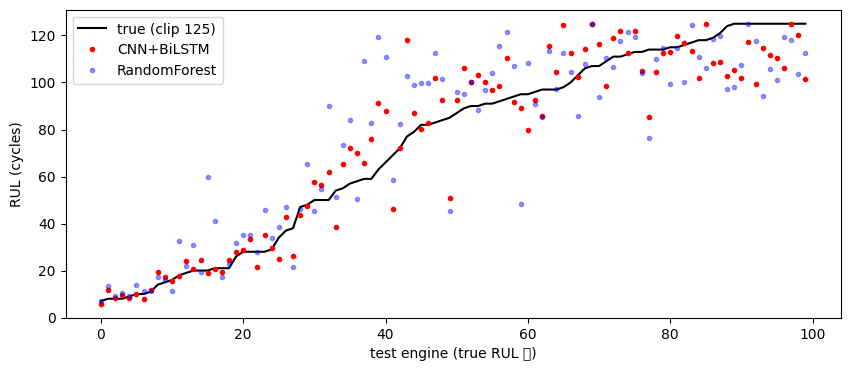

In [ ]:
import matplotlib.pyplot as plt
order = np.argsort(rul_true)
plt.figure(figsize=(10, 4))
plt.plot(np.minimum(rul_true, RUL_CAP)[order], 'k-', label='true (clip 125)')
plt.plot(np.clip(pred_dl, 0, RUL_CAP)[order], 'r.', label='CNN+BiLSTM')
plt.plot(np.clip(pred_rf, 0, RUL_CAP)[order], 'b.', alpha=0.4, label='RandomForest')
plt.xlabel('test engine (sorted by true RUL)'); plt.ylabel('RUL (cycles)'); plt.legend(); plt.show()

In [ ]:
# 시드 5개 평균 (시간이 걸리면 range(3)으로 줄이기)
res = []
for s in range(5):
    m = train_model(seed=s)
    p = np.clip(predict(m, X_test), 0, RUL_CAP)
    res.append((rmse(p, np.minimum(rul_true, RUL_CAP)), rmse(p, rul_true), nasa_score(p, rul_true)))
res = np.array(res)
print('RMSE(clip) %.2f ± %.2f | RMSE(raw) %.2f ± %.2f | Score %.0f ± %.0f' %
      (res[:,0].mean(), res[:,0].std(), res[:,1].mean(), res[:,1].std(), res[:,2].mean(), res[:,2].std()))

ep  1  train_rmse= 53.34  val_rmse= 26.26
ep  5  train_rmse= 17.92  val_rmse= 14.75
ep 10  train_rmse= 15.64  val_rmse= 13.88
ep 15  train_rmse= 14.50  val_rmse= 13.46
ep 20  train_rmse= 14.18  val_rmse= 15.24
ep 25  train_rmse= 13.86  val_rmse= 13.81
ep 30  train_rmse= 13.37  val_rmse= 13.88
ep 35  train_rmse= 13.17  val_rmse= 13.11
ep 40  train_rmse= 13.01  val_rmse= 12.97
ep 45  train_rmse= 12.89  val_rmse= 12.94
ep 50  train_rmse= 12.80  val_rmse= 12.88
ep 55  train_rmse= 12.74  val_rmse= 12.90
ep 60  train_rmse= 12.63  val_rmse= 12.93
best val RMSE: 12.83
ep  1  train_rmse= 49.13  val_rmse= 28.78
ep  5  train_rmse= 17.00  val_rmse= 15.03
ep 10  train_rmse= 14.90  val_rmse= 14.65
ep 15  train_rmse= 14.24  val_rmse= 14.25
ep 20  train_rmse= 13.94  val_rmse= 14.48
ep 25  train_rmse= 13.51  val_rmse= 13.95
ep 30  train_rmse= 13.04  val_rmse= 13.42
ep 35  train_rmse= 12.77  val_rmse= 13.09
early stop @ 38
best val RMSE: 12.97
ep  1  train_rmse= 48.62  val_rmse= 26.94
ep  5  train_rmse=

## 7. 모델 저장 (이후 Inference Daemon에서 사용)
가중치와 함께 **센서 목록, 정규화 범위, 윈도우 길이**를 저장.서빙할 때 학습과 똑같은 전처리를 해야 하기 때문


In [ ]:
torch.save(model.state_dict(), BASE / 'models' / 'rul_cnn_bilstm_fd001.pt')
meta = {'sensor_cols': sensor_cols, 'min': mn.to_dict(), 'max': mx.to_dict(), 'window': W, 'rul_cap': RUL_CAP}
json.dump(meta, open(BASE / 'models' / 'rul_meta_fd001.json', 'w'), indent=1)
print(sorted(p.name for p in (BASE / 'models').iterdir()))

['rul_cnn_bilstm_fd001.pt', 'rul_meta_fd001.json']
